# Data exploration and cleaning

Run the cells from top to bottom. Engine volume is now included, with median
imputation inside the pipeline. Both the previous and tuned forests are compared.
Cleaning removes engines above 8 litres before the normal 80/20 split, so the
fresh results below use a different split from the earlier local experiments.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

DATA_DIR = Path("data") if Path("data").exists() else Path("../data")
df = pd.read_csv(DATA_DIR / "original_cars.csv", encoding="cp1251")
import sys
sys.path.insert(0, str(DATA_DIR.resolve().parent))
from data_cleaning import clean_engine_volume


## 1. Translate Cyrillic text

Some car and model names contained Cyrillic text. We used the same translations as in `data_cleaning.py`. The pattern below matches Cyrillic characters.

In [2]:
cyrillic_count = df.astype("string").apply(
    lambda column: column.str.count(r"[\u0400-\u052F]")
).sum().sum()
print(f"Cyrillic characters before translation: {int(cyrillic_count)}")

Cyrillic characters before translation: 4997


In [3]:
# Translate Cyrillic model names
model_translations = {
    "1103 Славута": "1103 Slavuta",
    "1102 Таврия": "1102 Tavria",
    "Патриот": "Patriot",
    "969М": "969M",
    "2705 GAZель": "2705 GAZelle",
    "Таврия-Нова": "Tavria-Nova",
    "3302 GAZель": "3302 GAZelle",
    "2752 Соболь": "2752 Sobol",
    "469Б": "469B",
    "Приора": "Priora",
    "969 Волынь": "969 Volyn",
    "3221 GAZель": "3221 GAZelle",
    "2190 Гранта": "2190 Granta",
    "2109 (Балтика)": "2109 (Baltika)",
    "Классические": "Classic"
}

df["model"] = df["model"].replace(model_translations)

# Translate Cyrillic descriptions names
description_translations = {
    "груз.": "Cargo",
    "груз": "Cargo",
    "пасс.": "Passenger",
    "пасс": "Passenger"
}

for original, english in description_translations.items():
    df["model"] = df["model"].str.replace(
        original,
        english,
        regex=False
    )

# Translate Cyrillic car manufacturer names
df["car"] = df["car"].replace({
    "ЛUAZ": "LuAZ"
})

In [4]:
cyrillic_count = df.astype("string").apply(
    lambda column: column.str.count(r"[\u0400-\u052F]")
).sum().sum()
print(f"Cyrillic characters after translation: {int(cyrillic_count)}")

Cyrillic characters after translation: 0


## 2. Retain engine volume

We retain `engV` because the local experiment improved validation performance.
We convert it to numeric values, remove engines above 8 litres after deduplication,
and leave missing values for training-only median imputation. The cutoff is a
project choice; it is not proof that every larger engine is an incorrect entry.


In [5]:
print(f"Rows missing engV: {df['engV'].isna().sum()}")

Rows missing engV: 434


In [6]:
df["engV"] = pd.to_numeric(df["engV"], errors="coerce")


In [7]:
print(f"Rows above 8 litres: {df['engV'].gt(8).sum()}")


Rows above 8 litres: 62


## 3. Remove duplicates and large engine volumes

We keep the original duplicate keys (all columns except `engV`) and retain the
first matching row, as in the previous experiment. We then exclude `engV > 8`.
Missing sizes are retained and will be filled separately within each training fold.


In [8]:
duplicate_keys = df.columns.drop("engV").tolist()
print(f"Duplicates before cleaning: {df.duplicated(subset=duplicate_keys).sum()}")


Duplicates before cleaning: 125


In [9]:
df = df.drop_duplicates(subset=duplicate_keys).copy()
df = clean_engine_volume(df)


Removed 62 rows with engV above 8 litres


In [10]:
print(f"Duplicates after cleaning: {df.duplicated(subset=duplicate_keys).sum()}")
print(f"Rows left: {len(df)}")


Duplicates after cleaning: 0
Rows left: 9389


## 4. Fill missing drive values

We fill missing `drive` values with `unknown`, keeping the rows without guessing whether the car has front, rear, or full drive.

In [11]:
print(f"Missing drive values before filling: {df['drive'].isna().sum()}")

Missing drive values before filling: 500


In [12]:
df["drive"] = df["drive"].fillna("unknown")

In [13]:
print(f"Missing drive values after filling: {df['drive'].isna().sum()}")
df["drive"].value_counts()

Missing drive values after filling: 0


drive
front      5138
full       2404
rear       1347
unknown     500
Name: count, dtype: int64

## 5. Separate rows without valid prices

We keep rows with zero or invalid prices in a separate file for later predictions. Only positive, finite prices go into the cleaned dataset.

In [14]:
prices = pd.to_numeric(df["price"], errors="coerce")
valid_prices = prices.notna() & np.isfinite(prices) & (prices > 0)

print(f"Rows with zero prices: {(prices == 0).sum()}")
print(f"Rows without valid prices: {(~valid_prices).sum()}")

Rows with zero prices: 237
Rows without valid prices: 237


In [15]:
bad_rows = df[~valid_prices].index
without_prices_df = df.loc[bad_rows].copy()
cleaned_df = df.drop(bad_rows)
cleaned_df["price"] = pd.to_numeric(cleaned_df["price"])

In [16]:
print(f"Rows with zero prices after cleaning: {(cleaned_df['price'] == 0).sum()}")
print(f"Rows in cleaned data: {len(cleaned_df)}")
print(f"Rows kept for later prediction: {len(without_prices_df)}")

Rows with zero prices after cleaning: 0
Rows in cleaned data: 9152
Rows kept for later prediction: 237


## 6. Save the results

Save `cars_cleaned.csv` for training and `cars_without_prices.csv` for later
prediction. Both retain engine volume, exclude sizes above 8 litres, and fill
missing drive categories with `unknown`. Missing engine sizes stay blank in the
CSV: calculating a median on the full dataset would leak validation information.


In [17]:
cleaned_df.to_csv(DATA_DIR / "cars_cleaned.csv", index=False, encoding="utf-8")
without_prices_df.to_csv(DATA_DIR / "cars_without_prices.csv", index=False, encoding="utf-8")

## 7. Training data exploration

We plot only the training rows from the same split as `model_training.py`.


In [18]:
import sys
import matplotlib.pyplot as plt

sys.path.insert(0, str(DATA_DIR.resolve().parent))
from model_training import split_data

X_train, X_test, y_train, y_test = split_data(cleaned_df)
print(f"Training rows used in the plots: {len(X_train)}")

Training rows used in the plots: 7321


### 7.1 Price distribution

We show prices from 0 to 50,000 to see the main distribution more clearly. Cars priced above 50,000 stay in the dataset, but are outside this plot's range.


Cars shown: 6965 of 7321
Cars above this view: 356


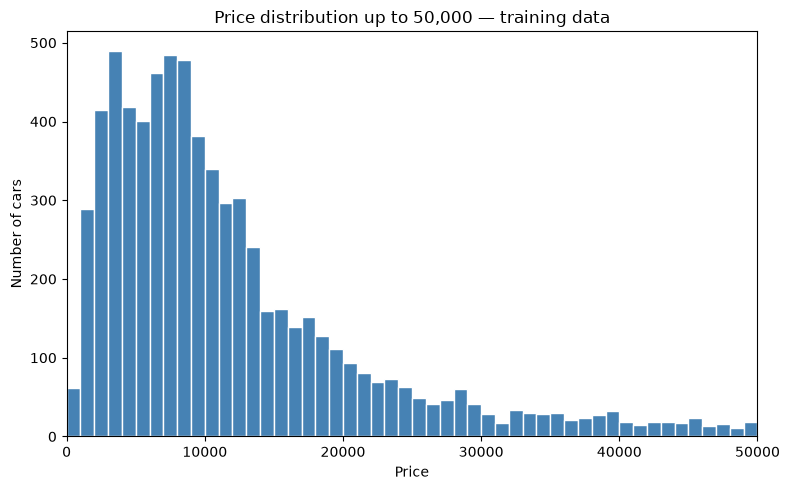

In [19]:
price_limit = 50000
print(f"Cars shown: {(y_train <= price_limit).sum()} of {len(y_train)}")
print(f"Cars above this view: {(y_train > price_limit).sum()}")

plt.figure(figsize=(8, 5))
plt.hist(y_train, bins=50, range=(0, price_limit), color="steelblue", edgecolor="white")
plt.xlim(0, price_limit)
plt.title("Price distribution up to 50,000 — training data")
plt.xlabel("Price")
plt.ylabel("Number of cars")
plt.tight_layout()
plt.show()

### 7.2 Price and year

Each dot is one car. We can look for a relationship between the car's year and its price.


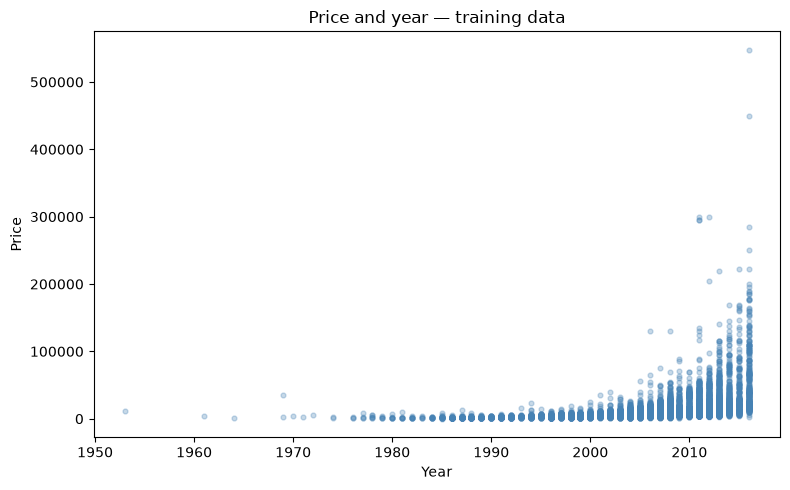

In [20]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train["year"], y_train, s=12, alpha=0.3, color="steelblue")
plt.title("Price and year — training data")
plt.xlabel("Year")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

### 7.3 Price and mileage

Each dot is one car. We can look for a relationship between mileage and price.


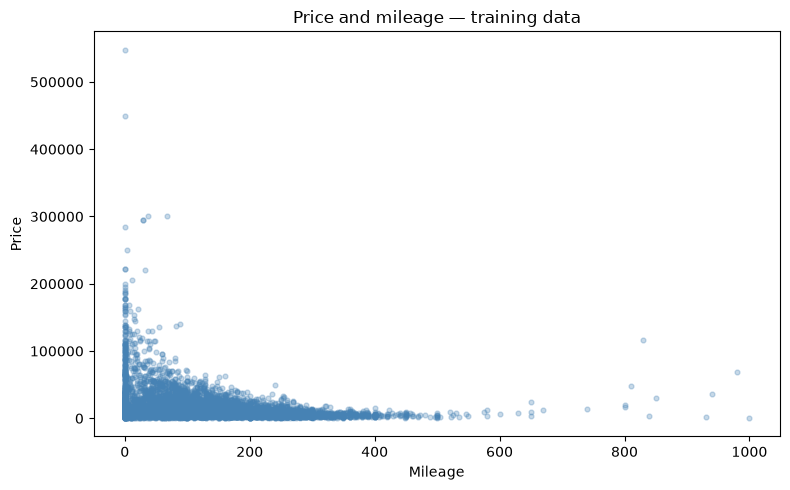

In [21]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train["mileage"], y_train, s=12, alpha=0.3, color="steelblue")
plt.title("Price and mileage — training data")
plt.xlabel("Mileage")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

## 8. Prepare input features

We use median imputation and standardization for mileage, year, and engine volume,
and one-hot encoding for categories. All preparation is fitted inside each
pipeline, using training rows only. This matches `create_preprocessor()`.


### 8.1 Set up the preparation

`SimpleImputer(strategy="median")` fills missing numeric values with the training
median, then `StandardScaler` rescales them. Each validation fold learns its own
median and scales. `OneHotEncoder(handle_unknown="ignore")` converts categories
to 0/1 columns and accepts categories not seen during fitting.

Lecture 3 discusses missing-data preparation; Lecture 4 supports training-only
preparation and cross-validation. Median imputation is our project choice.


In [22]:
from model_training import create_preprocessor
preprocessor = create_preprocessor()


### 8.2 Prepare the training rows

`fit_transform()` learns the scaling values and category names from `X_train`, then converts it to numeric inputs. We keep `price` unchanged and leave the test set aside.


In [23]:
X_train_prepared = preprocessor.fit_transform(X_train)
print(f"Rows: {X_train_prepared.shape[0]}")
print(f"Features before preparation: {X_train.shape[1]}")
print(f"Features after preparation: {X_train_prepared.shape[1]}")

Rows: 7321
Features before preparation: 9
Features after preparation: 924


### 8.3 See the scaled numbers

This table compares the original and scaled values for five training cars. A negative scaled value means it is below the training average. Scaling changes the scale, not the underlying information.


In [24]:
prepared_example = pd.DataFrame(
    X_train_prepared[:5].toarray(),
    columns=preprocessor.get_feature_names_out(),
    index=X_train.head().index,
)
numeric_example = X_train[["mileage", "year", "engV"]].head().copy()
for column in ["mileage", "year", "engV"]:
    numeric_example[column + "_scaled"] = prepared_example["numeric__" + column]
numeric_example.round(2)


,mileage,year,engV,mileage_scaled,year_scaled,engV_scaled
5486,145,2006,1.6,0.04,-0.08,-0.65
3512,111,1989,2.0,-0.31,-2.56,-0.23
5587,25,2014,NaN,-1.19,1.09,-0.23
4245,70,2013,1.8,-0.73,0.94,-0.44
2594,88,2010,4.2,-0.54,0.51,2.08


### 8.4 See the encoded drive categories

A value of 1 means the car belongs to that category; 0 means it does not. `unknown` is its own category, just like front, rear, and full drive.


In [25]:
drive_example = prepared_example.filter(like="drive_").copy()
drive_example["drive_before_encoding"] = X_train["drive"].head()
drive_example

,categorical__drive_front,categorical__drive_full,categorical__drive_rear,categorical__drive_unknown,drive_before_encoding
5486,0.0,0.0,0.0,1.0,unknown
3512,0.0,0.0,1.0,0.0,rear
5587,1.0,0.0,0.0,0.0,front
4245,1.0,0.0,0.0,0.0,front
2594,0.0,1.0,0.0,0.0,full


## 9. Train the first regression model

We train linear regression using the prepared features and training prices. We compare this first model with other models later.


### 9.1 Combine preparation and the model

A `Pipeline` runs preparation followed by regression. We give it the original input columns; it handles scaling and encoding. This is the same setup as `create_model()` in `model_training.py`.


In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from model_training import create_preprocessor

model = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("regressor", LinearRegression()),
])

### 9.2 Train the model

`fit()` learns from the training cars and their known prices. The pipeline fits both the preparation and regression using training data only.


In [27]:
model.fit(X_train, y_train)
print(f"Linear regression trained on {len(X_train)} cars.")

Linear regression trained on 7321 cars.


### 9.3 Show example predictions

We predict prices for five training cars and compare them with their actual prices. The model has already seen these cars, so these examples do not tell us how well it predicts new cars. Validation comes in the next step.


In [28]:
examples = X_train[["car", "model", "year", "mileage"]].head().copy()
examples["actual_price"] = y_train.head()
examples["predicted_price"] = model.predict(X_train.head())
examples.round(2)

,car,model,year,mileage,actual_price,predicted_price
5486,VAZ,2111,2006,145,3650.0,780.12
3512,Ford,Sierra,1989,111,1350.0,4860.91
5587,Nissan,Leaf,2014,25,17000.0,17218.29
4245,Geely,Emgrand 7 (EC7),2013,70,5300.0,6279.01
2594,Audi,Q7,2010,88,41000.0,39944.31


### 9.4 Plot the training predictions

Each dot compares one training car's actual and predicted price. A dot on the dashed line is an exact match. This is a view of the training fit; the test set remains aside.

Linear regression can predict negative prices because it does not restrict the output to positive values. We keep the raw predictions visible for review.


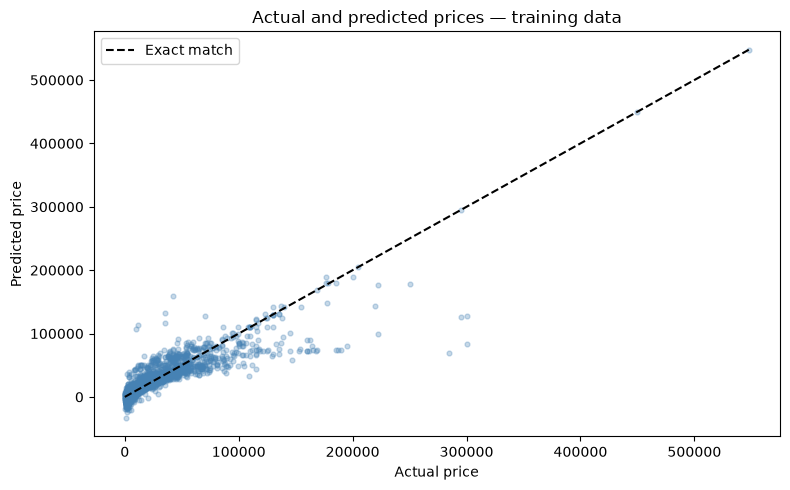

In [29]:
training_predictions = model.predict(X_train)
price_max = max(y_train.max(), training_predictions.max())

plt.figure(figsize=(8, 5))
plt.scatter(y_train, training_predictions, s=12, alpha=0.3, color="steelblue")
plt.plot([0, price_max], [0, price_max], "k--", label="Exact match")
plt.title("Actual and predicted prices — training data")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Validate linear regression

We split the cleaned data into 80% training and 20% held-out test data, with
`random_state=42`. Five-fold cross-validation trains on four parts and validates
on the remaining part. Every training car is validated once; the test set stays
aside. Counts are calculated from the cleaned data rather than fixed in the text.


### 10.1 Run five-fold cross-validation

We pass a fresh pipeline to `cross_validate()`. It refits preprocessing and regression inside each fold. We use the original `X_train`, so preparation does not learn from the validation rows.

MAE is the average absolute price error. RMSE gives more weight to large errors. Both use the same units as price, and lower values are better.


In [30]:
from sklearn.model_selection import KFold, cross_validate
from model_training import create_model, SCORING

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(
    create_model(),
    X_train,
    y_train,
    cv=cv,
    scoring=SCORING,
    return_train_score=True,
    error_score="raise",
)

### 10.2 Show the errors for each fold

Scikit-learn returns negative error scores, so we use a minus sign to show positive errors. Its `test_MAE` and `test_RMSE` keys refer to the validation fold, not our held-out test dataset. This is the same procedure used by `validate_linear_regression()` and `validate_model()` in `model_training.py`.


In [31]:
fold_results = pd.DataFrame({
    "fold": range(1, 6),
    "training_MAE": -scores["train_MAE"],
    "validation_MAE": -scores["test_MAE"],
    "training_RMSE": -scores["train_RMSE"],
    "validation_RMSE": -scores["test_RMSE"],
    "validation_within20_percent": 100 * scores["test_within20"],
})
fold_results.round(2)

,fold,training_MAE,validation_MAE,training_RMSE,validation_RMSE,validation_within20_percent
0,1,4771.64,5410.24,10763.65,9836.73,39.93
1,2,4513.52,6371.13,9742.99,16498.64,40.30
2,3,4414.02,6600.82,9646.56,17477.94,39.82
3,4,4577.72,6069.49,10055.60,14722.37,39.34
4,5,4798.56,5857.23,10799.73,11886.29,37.23


### 10.3 Summarize the five folds

`mean` is the average error across the folds. `std` shows how much the errors vary between folds. Comparing training and validation errors helps us see whether performance drops on unseen cars.


In [32]:
summary = fold_results.drop(columns=["fold"]).agg(["mean", "std"]).T
summary.round(2)

,mean,std
training_MAE,4615.09,166.07
validation_MAE,6061.78,461.70
training_RMSE,10201.71,550.76
validation_RMSE,14084.39,3186.93
validation_within20_percent,39.33,1.22


## 11. Train and validate a decision tree

We train a decision tree using the same prepared features. We start with default tree settings and `random_state=42` to make training repeatable. We compare its errors with linear regression using the same five folds. The held-out test set stays aside.


### 11.1 Create the decision tree pipeline

We use the same preparation as linear regression and replace the regressor. Trees do not require numeric scaling, but we keep the existing preparation for this first comparison. This matches `create_decision_tree_model()` in `model_training.py`.


In [33]:
from sklearn.tree import DecisionTreeRegressor
from model_training import create_decision_tree_model

tree_model = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("regressor", DecisionTreeRegressor(random_state=42)),
])

### 11.2 Train and show example predictions

The table shows five training cars. These examples illustrate the fitted tree; validation below measures predictions for cars it has not trained on.


In [34]:
tree_model.fit(X_train, y_train)

tree_examples = X_train[["car", "model", "year", "mileage"]].head().copy()
tree_examples["actual_price"] = y_train.head()
tree_examples["predicted_price"] = tree_model.predict(X_train.head())
tree_examples.round(2)

,car,model,year,mileage,actual_price,predicted_price
5486,VAZ,2111,2006,145,3650.0,3650.0
3512,Ford,Sierra,1989,111,1350.0,1350.0
5587,Nissan,Leaf,2014,25,17000.0,17000.0
4245,Geely,Emgrand 7 (EC7),2013,70,5300.0,5300.0
2594,Audi,Q7,2010,88,41000.0,41000.0


### 11.3 Validate using the same five folds

We reuse `cv` from section 10 so both models are evaluated on exactly the same folds. A fresh tree pipeline is fitted within each fold, using the original inputs rather than already prepared data.


In [35]:
tree_scores = cross_validate(
    create_decision_tree_model(),
    X_train,
    y_train,
    cv=cv,
    scoring=SCORING,
    return_train_score=True,
    error_score="raise",
)

### 11.4 Show decision tree errors

We show positive MAE and RMSE for training and validation, using the same calculation as section 10.


In [36]:
tree_fold_results = pd.DataFrame({
    "fold": range(1, 6),
    "training_MAE": -tree_scores["train_MAE"],
    "validation_MAE": -tree_scores["test_MAE"],
    "training_RMSE": -tree_scores["train_RMSE"],
    "validation_RMSE": -tree_scores["test_RMSE"],
    "validation_within20_percent": 100 * tree_scores["test_within20"],
})
tree_fold_results.round(2)

,fold,training_MAE,validation_MAE,training_RMSE,validation_RMSE,validation_within20_percent
0,1,61.44,3129.38,1109.28,8462.22,60.82
1,2,60.78,3647.22,1095.38,11272.58,61.95
2,3,40.93,4637.98,479.45,19015.31,59.97
3,4,53.49,3525.00,1054.83,11330.17,60.04
4,5,55.32,3518.97,1104.46,10523.41,61.13


### 11.5 Compare with linear regression

These are the mean errors across the same five folds. Lower validation errors are better. A large gap between training and validation errors suggests overfitting. Low training error alone does not mean the model predicts new cars well.


In [37]:
comparison = pd.DataFrame({
    "Linear regression": fold_results.drop(columns=["fold"]).mean(),
    "Decision tree": tree_fold_results.drop(columns=["fold"]).mean(),
}).T
comparison.round(2)

,training_MAE,validation_MAE,training_RMSE,validation_RMSE,validation_within20_percent
Linear regression,4615.09,6061.78,10201.71,14084.39,39.33
Decision tree,54.39,3691.71,968.68,12120.74,60.78


## 12. Train and validate a random forest

We train a random forest with 100 trees and compare it with the other models. For regression, the forest averages the trees' predictions.

`max_features="sqrt"` lets each split consider a random subset of the input features. `random_state=42` makes training repeatable. These are our starting settings. Tuning comes later.


### 12.1 Create the random forest pipeline

We keep the same feature preparation and replace the regressor. This matches `create_random_forest_model()` in `model_training.py`.


In [38]:
from sklearn.ensemble import RandomForestRegressor
from model_training import create_random_forest_model

forest_model = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("regressor", RandomForestRegressor(
        n_estimators=100, max_features="sqrt", random_state=42
    )),
])

### 12.2 Train and show example predictions

These five cars are from the training data. The table illustrates the fitted forest; validation below checks predictions for unseen cars.


In [39]:
forest_model.fit(X_train, y_train)

forest_examples = X_train[["car", "model", "year", "mileage"]].head().copy()
forest_examples["actual_price"] = y_train.head()
forest_examples["predicted_price"] = forest_model.predict(X_train.head())
forest_examples.round(2)

,car,model,year,mileage,actual_price,predicted_price
5486,VAZ,2111,2006,145,3650.0,3810.46
3512,Ford,Sierra,1989,111,1350.0,2454.57
5587,Nissan,Leaf,2014,25,17000.0,16699.52
4245,Geely,Emgrand 7 (EC7),2013,70,5300.0,6988.43
2594,Audi,Q7,2010,88,41000.0,41878.85


### 12.3 Validate using the same five folds

We reuse `cv` from section 10. The forest and its preparation are fitted again inside each fold. The held-out test set remains aside.


In [40]:
forest_scores = cross_validate(
    create_random_forest_model(),
    X_train,
    y_train,
    cv=cv,
    scoring=SCORING,
    return_train_score=True,
    error_score="raise",
)

### 12.4 Show random forest errors

We show positive training and validation errors using the same metrics as the other models.


In [41]:
forest_fold_results = pd.DataFrame({
    "fold": range(1, 6),
    "training_MAE": -forest_scores["train_MAE"],
    "validation_MAE": -forest_scores["test_MAE"],
    "training_RMSE": -forest_scores["train_RMSE"],
    "validation_RMSE": -forest_scores["test_RMSE"],
    "validation_within20_percent": 100 * forest_scores["test_within20"],
})
forest_fold_results.round(2)

,fold,training_MAE,validation_MAE,training_RMSE,validation_RMSE,validation_within20_percent
0,1,1194.30,2407.35,4291.24,4433.35,67.92
1,2,1158.75,3269.76,4371.42,11504.19,65.92
2,3,1090.50,3454.12,3298.57,14670.43,63.73
3,4,1165.65,3320.26,4012.96,11684.75,64.89
4,5,1162.09,2824.56,4133.70,7648.86,66.87


### 12.5 Compare the previous and tuned forests with other models

Both forests now include engine volume and use identical median-imputation
pipelines. The previous forest uses 100 trees and `max_features="sqrt"`.
The tuned candidate uses 300 trees, `max_features=0.5`, `max_depth=30`, and
`min_samples_leaf=1`. Half of the encoded columns are candidates at each split.
Lecture 6 discusses forest feature sampling and limiting tree depth.

We compare training and validation MAE/RMSE to investigate overfitting. The last
column reports the percentage within 20% of actual price; higher is better.
These settings were already selected using validation data, so the tuned
validation score is not an independent test result.


In [42]:
from model_training import create_tuned_random_forest_model, validate_model

tuned_fold_results = validate_model(create_tuned_random_forest_model(), X_train, y_train)

comparison = pd.DataFrame({
    "Linear regression": fold_results.drop(columns=["fold"]).mean(),
    "Decision tree": tree_fold_results.drop(columns=["fold"]).mean(),
    "Random forest": forest_fold_results.drop(columns=["fold"]).mean(),
    "Tuned forest with engV": tuned_fold_results.drop(columns=["fold"]).mean(),
}).T
comparison.round(2)

,training_MAE,validation_MAE,training_RMSE,validation_RMSE,validation_within20_percent
Linear regression,4615.09,6061.78,10201.71,14084.39,39.33
Decision tree,54.39,3691.71,968.68,12120.74,60.78
Random forest,1154.26,3055.21,4021.58,9988.32,65.87
Tuned forest with engV,1105.73,2846.65,3758.48,9249.42,69.77


## 13. Tune the random forest

The earlier local experiment, with its original fold assignments, produced:

| Forest with engV | Pooled validation MAE (USD) | Pooled RMSE (USD) | Within 20% |
|---|---:|---:|---:|
| Previous settings | 2975.80 | 9936.44 | 66.44% |
| Tuned settings | 2853.99 | 9611.81 | 70.40% |

Those historical scores motivated this change. The normal cleaning workflow
now filters before splitting; the current results below therefore differ.
We search 13 configurations using the same five folds for all candidates,
selecting by the lowest mean validation MAE. The test set remains reserved.


### 13.1 Choose the settings to try

We compare 12 structures with 100 trees: `max_features` in ["sqrt", 0.5, 1.0],
`max_depth` in [None, 30], and `min_samples_leaf` in [1, 2]. We also include the
earlier selected 300-tree candidate with depth 30, feature fraction 0.5, and leaf
size 1. These are project choices, not guaranteed optimal settings.
`tune_random_forest()` performs the search and refits its winner on all training
rows. The `regressor__` prefix selects settings of the pipeline's forest step.


In [43]:
from model_training import tune_random_forest, summarize_tuning


### 13.2 Run the search

Thirteen configurations and five folds require 65 validation fits, followed by
one fit of the selected pipeline on all training rows. Every fit learns its own
imputation median, scaling values, and categories.


In [44]:
grid_search = tune_random_forest(X_train, y_train)
print("Grid search finished.")


Grid search finished.


### 13.3 Show all combinations

The table is sorted by validation MAE, with lower errors first. All errors are averages across the five folds. `unlimited` means no depth limit. This matches `summarize_tuning()` in `model_training.py`.


In [45]:
grid_results = summarize_tuning(grid_search)
grid_results.round(2)


,n_estimators,max_features,max_depth,min_samples_leaf,training_MAE,validation_MAE,training_RMSE,validation_RMSE,validation_within20_percent
12,300,0.5,30,1,1105.73,2846.65,3758.48,9249.42,69.77
8,100,0.5,30,1,1117.04,2858.93,3777.58,9329.07,69.96
2,100,0.5,unlimited,1,1072.27,2880.65,3788.90,9451.33,69.87
10,100,1.0,30,1,1130.80,2940.72,3820.11,9531.41,69.44
4,100,1.0,unlimited,1,1091.58,2945.86,3822.05,9563.25,69.51
3,100,0.5,unlimited,2,1770.57,3018.75,6156.16,9295.63,67.86
9,100,0.5,30,2,1768.02,3025.68,6154.84,9322.12,67.64
0,100,sqrt,unlimited,1,1154.26,3055.21,4021.58,9988.32,65.87
11,100,1.0,30,2,1656.01,3099.18,5705.74,9381.92,67.46
5,100,1.0,unlimited,2,1652.23,3100.84,5703.58,9408.84,67.56


### 13.4 Compare the selected settings with the initial forest

We compare both versions using the same validation folds. The selected settings may be the original settings if none of the others improves validation MAE. These scores helped choose the settings; final test performance is still unknown.


In [46]:
print(f"Selected settings: {grid_search.best_params_}")
tuned_errors = grid_results.loc[grid_search.best_index_, comparison.columns].astype(float)
tuning_comparison = pd.DataFrame({
    "Initial random forest": comparison.loc["Random forest"],
    "Selected random forest": tuned_errors,
}).T
tuning_comparison.round(2)

Selected settings: {'regressor__max_depth': 30, 'regressor__max_features': 0.5, 'regressor__min_samples_leaf': 1, 'regressor__n_estimators': 300}


,training_MAE,validation_MAE,training_RMSE,validation_RMSE,validation_within20_percent
Initial random forest,1154.26,3055.21,4021.58,9988.32,65.87
Selected random forest,1105.73,2846.65,3758.48,9249.42,69.77


### 13.5 Keep the selected pipeline

`best_estimator_` contains the selected forest and its preparation, already fitted on all training rows. This is the fitted pipeline we evaluate in the next section.


In [47]:
best_model = grid_search.best_estimator_
print(f"Selected pipeline fitted on {len(X_train)} training cars.")

Selected pipeline fitted on 7321 training cars.


## 14. Final test evaluation

We evaluate the selected, fitted pipeline on the held-out rows after comparing
and tuning models. We do not change settings based on the test results. This
test set belongs to the updated preparation and split; it is not the original
test set used before the engine-volume change.


### 14.1 Predict test prices and calculate errors

`predict()` uses the preparation already learned from training data. We do not call `fit()` on the test rows. This matches `evaluate_final_model()` in `model_training.py`.


In [48]:
from model_training import evaluate_final_model

test_predictions, test_results = evaluate_final_model(best_model, X_test, y_test)
print(f"Test rows evaluated: {len(X_test)}")
test_results.round(2)


Test rows evaluated: 1831


,MAE,RMSE,within20_percent
Held-out test,2590.5,7195.91,72.26


### 14.2 Compare validation and final test errors

The validation row is the average across five folds used during model selection. The test row evaluates the selected pipeline on held-out cars. Different cars and training sizes mean the errors can differ.

We record these final test results without using them to change settings.


In [49]:
final_comparison = pd.DataFrame({
    "MAE": [tuning_comparison.loc["Selected random forest", "validation_MAE"],
            test_results.loc["Held-out test", "MAE"]],
    "RMSE": [tuning_comparison.loc["Selected random forest", "validation_RMSE"],
             test_results.loc["Held-out test", "RMSE"]],
    "within20_percent": [tuning_comparison.loc["Selected random forest", "validation_within20_percent"],
                         test_results.loc["Held-out test", "within20_percent"]],
}, index=["Cross-validation (mean)", "Held-out test"])
final_comparison.round(2)

,MAE,RMSE,within20_percent
Cross-validation (mean),2846.65,9249.42,69.77
Held-out test,2590.50,7195.91,72.26


### 14.3 Show five test predictions

We show the first five test cars using the predictions already calculated above. `absolute_error` is the size of the difference between the actual and predicted price.


In [50]:
test_examples = X_test[["car", "model", "year", "mileage"]].head().copy()
test_examples["actual_price"] = y_test.head()
test_examples["predicted_price"] = test_predictions[:5]
test_examples["absolute_error"] = (
    test_examples["actual_price"] - test_examples["predicted_price"]
).abs()
test_examples.round(2)

,car,model,year,mileage,actual_price,predicted_price,absolute_error
6961,Audi,S4,2008,115,23000.0,12994.03,10005.97
2346,Volkswagen,Passat B5,2002,250,8700.0,8322.13,377.87
2982,Peugeot,Partner Passenger,2007,112,6300.0,7776.84,1476.84
6217,Nissan,Leaf,2015,10,22500.0,18443.96,4056.04
9574,Lexus,ES 350,2008,150,16999.0,17208.03,209.03


## 15. Save the selected pipeline

We save the fitted preprocessing and random forest together using `joblib`, so they can be loaded for later predictions.

The saved pipeline expects mileage in thousands: 68 represents 68,000. Saving does not train the model again. This matches `save_pipeline()` in `model_training.py`.

The saved pipeline also expects `engV` in litres. A missing value (`NaN`) is filled
with the median learned during fitting. The app accepts known or unknown volume.


In [51]:
import joblib
from model_training import MODEL_PATH

MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(best_model, MODEL_PATH, compress=3)
print(f"Saved pipeline to {MODEL_PATH}")

Saved pipeline to E:\Github\UsedCarPricePredicator-Dat158\models\car_price_pipeline.joblib
